# Phase 2: Exploratory Analysis and Preregistration
**NOAA data imported and merged:** All 813 month–material rows have temperature and precipitation values.

Sales coverage, quantity units, and material labels still need verification. The two proposed regressions have not been run.


## Part 1 — Data collection and exploratory analysis
### 1. Research question
**How are contiguous U.S. monthly temperature and precipitation associated with the business’s monthly hat sales, and does the relationship differ by hat material?**

We measure monthly quantity by material. Until we confirm whether `Qty` means hats or packs, we label it *recorded quantity*. NOAA’s CONUS series covers the lower 48 states. We study associations with this business’s sales, not causal effects or national hat demand.


### 2. Data collection and cleaning
#### Data sources and collection
The business supplied accounting exports, and the group downloaded NOAA climate data. All files are stored in `csvs/`; no downloads run in this notebook.

| File | Use |
| --- | --- |
| `salesByCustomerDetail.CSV` | Invoice lines used to calculate monthly sales. |
| `itemData.CSV` | Product descriptions used to identify hats and materials. |
| `inventoryData.CSV` | Coverage checks only; adding its invoices could double-count sales. |
| `TempreatureData.CSV` | CONUS mean temperature, converted from °F to °C. |
| `PrecipitationData.CSV` | CONUS precipitation, converted from inches to mm. |

Weather source: [NOAA monthly nClimDiv directory](https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/). We join the cleaned sources by calendar month.


#### Setup
Run from the repository root, which contains `csvs`. We use pandas for tables and matplotlib for plots.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# All file paths are relative to the repository root.
plt.rcParams['figure.figsize'] = (10, 4)


#### Load the business files
Read columns as text to preserve item IDs. Sales and catalog files use Windows-1252; inventory uses UTF-8. Outputs show row counts and transaction types.


In [2]:
# Load the three original accounting exports.
sales_raw = pd.read_csv('csvs/salesByCustomerDetail.CSV', encoding='cp1252', dtype=str).fillna('')
catalog = pd.read_csv('csvs/itemData.CSV', encoding='cp1252', dtype=str).fillna('')
inventory = pd.read_csv('csvs/inventoryData.CSV', encoding='utf-8-sig', dtype=str).fillna('')

print('Sales report rows:', len(sales_raw))
print('Catalog rows:', len(catalog))
print('Inventory report rows:', len(inventory))
print('Sales row types (blank = report heading or subtotal):')
display(sales_raw['Type'].value_counts())
print('Inventory row types:')
display(inventory['Type'].value_counts())


Sales report rows: 32768
Catalog rows: 7866
Inventory report rows: 32768
Sales row types (blank = report heading or subtotal):
Inventory row types:


Type
Invoice    31877
             891
Name: count, dtype: int64

Type
Invoice             29954
Item Receipt         1154
                      846
Inventory Adjust      700
Build Assembly         99
Bill                   15
Name: count, dtype: int64

#### Parse invoices and match the catalog
Keep invoices, clean dates and numbers, and match item IDs to the catalog. Retain source row numbers and duplicate-looking lines, which may be legitimate.

**Coverage concern:** Both transaction exports have 32,768 rows and end mid-group, suggesting an export limit. Verify report completeness before modeling.


In [3]:
# Keep invoice rows, rather than report headings and subtotals.
sales = sales_raw[sales_raw['Type'] == 'Invoice'].copy()
sales['source_csv_row'] = sales.index + 2
sales['date'] = pd.to_datetime(sales['Date'], format='%m/%d/%Y', errors='coerce')

# Clean the three numeric columns. Parentheses mean a negative amount.
for column in ['Qty', 'Amount', 'Sales Price']:
    sales[column] = sales[column].str.replace(',', '', regex=False)
    sales[column] = sales[column].str.replace('$', '', regex=False)
    sales[column] = sales[column].str.replace('(', '-', regex=False)
    sales[column] = sales[column].str.replace(')', '', regex=False)
    sales[column] = pd.to_numeric(sales[column], errors='coerce')
sales = sales.rename(columns={'Qty': 'quantity', 'Amount': 'amount', 'Sales Price': 'unit_price'})

# Sales item names contain an ID followed by a description in parentheses.
sales['item_id'] = sales['Item'].str.split(' (', n=1, regex=False).str[0].str.strip()
catalog['item_id'] = catalog['Item'].str.strip()
products = catalog[['item_id', 'Type', 'Description']].copy()
products = products.rename(columns={'Type': 'catalog_type', 'Description': 'catalog_description'})

# many_to_one checks that each item ID matches no more than one catalog row.
sales = sales.merge(products, on='item_id', how='left', validate='many_to_one')
print('Invoice lines:', len(sales))
print('Unmatched catalog lines:', sales['catalog_type'].isna().sum())
print('First invoice date:', sales['date'].min())
print('Last invoice date:', sales['date'].max())
print('Missing numeric values:')
display(sales[['quantity', 'amount', 'unit_price']].isna().sum())
print('Zero or negative quantity lines:', (sales['quantity'] <= 0).sum())
print('Duplicate-looking source lines retained:', sales_raw[sales_raw['Type'] == 'Invoice'].duplicated().sum())


Invoice lines: 31877
Unmatched catalog lines: 1
First invoice date: 2006-10-01 00:00:00
Last invoice date: 2026-08-13 00:00:00
Missing numeric values:
Zero or negative quantity lines: 422
Duplicate-looking source lines retained: 1


quantity         0
amount         466
unit_price    1089
dtype: int64

#### Identify candidate hats and material labels
Use catalog types and hat-related words to select candidate hats. Match material words; multiple matches become `mixed_or_ambiguous`, and no match becomes `unknown`. Labels need review because words may describe trim or construction.

Keep dated, positive quantities for preliminary gross sales. This does not account fully for returns or credits.


In [4]:
# Combine descriptions and replace punctuation with spaces for word matching.
sales['description_text'] = sales['catalog_description'].fillna('') + ' ' + sales['Item']
sales['description_text'] = sales['description_text'].str.lower()
sales['words'] = sales['description_text'].str.replace(r'[^a-z]+', ' ', regex=True)
sales['words'] = ' ' + sales['words'] + ' '

# Flag common hat words. Spaces help avoid matching a word inside another word.
hat_words = ['hat', 'hats', 'cap', 'caps', 'ivy', 'ivies', 'fedora', 'fedoras',
             'beanie', 'beanies', 'beret', 'berets', 'cloche', 'cloches',
             'fascinator', 'fascinators', 'visor', 'visors', 'bonnet', 'bonnets',
             'duckbill', 'newsboy', 'trilby', 'floppy', 'panama']
sales['candidate_hat'] = False
for word in hat_words:
    matches = sales['words'].str.contains(' ' + word + ' ', regex=False)
    sales.loc[matches, 'candidate_hat'] = True

# Exclude services, freight, and other non-merchandise catalog types.
merchandise_types = ['Inventory Part', 'Inventory Assembly', 'Non-inventory Part']
sales['candidate_hat'] = sales['candidate_hat'] & sales['catalog_type'].isin(merchandise_types)

# Assign a provisional material from explicit description words.
sales['material'] = 'unknown'
sales['material_matches'] = 0
for material in ['wool', 'straw', 'cotton', 'polyester', 'acrylic', 'leather', 'felt']:
    matches = sales['words'].str.contains(' ' + material + ' ', regex=False)
    if material == 'straw':
        matches = matches | sales['words'].str.contains(' raffia ', regex=False)
    sales.loc[matches, 'material'] = material
    sales.loc[matches, 'material_matches'] += 1
sales.loc[sales['material_matches'] > 1, 'material'] = 'mixed_or_ambiguous'

# Keep dated, positive-quantity candidate hats for preliminary gross-sales EDA.
keep = sales['candidate_hat'] & sales['date'].notna() & (sales['quantity'] > 0)
clean_sales = sales.loc[keep, ['source_csv_row', 'date', 'item_id', 'quantity',
                             'amount', 'unit_price', 'material']].copy()
clean_sales['month'] = clean_sales['date'].dt.to_period('M').dt.to_timestamp()
print('Retained candidate-hat invoice lines:', len(clean_sales))
display(clean_sales.groupby('material')['quantity'].sum().sort_values(ascending=False))


Retained candidate-hat invoice lines: 23072


material
unknown               696515
cotton                 29182
felt                   12937
wool                   10912
straw                   6117
mixed_or_ambiguous      5867
leather                 2553
polyester                288
Name: quantity, dtype: int64

#### Aggregate monthly sales
Sum quantities by month and material. Leave missing months unknown rather than assuming zero sales.


In [5]:
# Sum quantities for each month and material.
monthly_sales = clean_sales.groupby(['month', 'material'])['quantity'].sum().reset_index()
monthly_sales = monthly_sales.rename(columns={'quantity': 'recorded_quantity'})

# Make a calendar so gaps remain visible in the time-series plots.
month_range = pd.date_range(clean_sales['month'].min(), clean_sales['month'].max(), freq='MS')
observed_month_count = clean_sales['month'].nunique()
print('Observed sales months:', observed_month_count)
print('Months without retained observations:', len(month_range) - observed_month_count)
display(monthly_sales.head())


Observed sales months: 234
Months without retained observations: 5


,month,material,recorded_quantity
0,2006-10-01,unknown,15259
1,2006-11-01,unknown,25537
2,2006-12-01,unknown,22356
3,2007-01-01,unknown,10310
4,2007-02-01,unknown,6086


#### Load and clean NOAA monthly data
These `.CSV` files contain space-separated fields: an ID followed by 12 monthly values. [NOAA’s format guide](https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/state-readme.txt) defines the ID as region (characters 1–3), division (4), variable (5–6), and year (7–10).

Select region **110** (CONUS), division **0**, and variables **02** (temperature) and **01** (precipitation). NOAA already supplies area-weighted monthly estimates. Precipitation is the area average of monthly totals.

Both series cover 1895–September 2026. We use October 2006–August 2026 to match the sales calendar. Record the original release filenames and download date before submission.


In [6]:
# Read the ID and 12 monthly values. \s+ means one or more whitespace characters.
month_columns = ['01', '02', '03', '04', '05', '06',
                 '07', '08', '09', '10', '11', '12']
column_names = ['code'] + month_columns
temperature_raw = pd.read_csv('csvs/TempreatureData.CSV', sep=r'\s+',
                              header=None, names=column_names, dtype={'code': str})
precipitation_raw = pd.read_csv('csvs/PrecipitationData.CSV', sep=r'\s+',
                                header=None, names=column_names, dtype={'code': str})

# The six-character prefix selects region 110, division 0, and the variable.
temperature = temperature_raw[temperature_raw['code'].str[:6] == '110002'].copy()
precipitation = precipitation_raw[precipitation_raw['code'].str[:6] == '110001'].copy()
temperature['year'] = temperature['code'].str[6:10]
precipitation['year'] = precipitation['code'].str[6:10]
print('National temperature years:', len(temperature))
print('National precipitation years:', len(precipitation))
display(temperature[['year'] + month_columns].tail(2))


National temperature years: 132
National precipitation years: 132


,year,01,02,03,04,05,06,07,08,09,10,11,12
7792,2025,29.16,34.74,46.83,53.56,61.70,71.20,75.42,73.38,67.95,56.95,46.69,37.83
7793,2026,33.12,40.26,50.85,54.77,61.68,70.66,76.91,75.54,69.42,-99.90,-99.90,-99.90


#### Reshape and convert temperature
Use `melt` to make one row per month. Replace missing code `-99.90`, then convert °F to °C.


In [7]:
# Reshape the national temperature rows into one row per month.
temperature_monthly = temperature.melt(id_vars='year', value_vars=month_columns,
                                     var_name='month_number', value_name='temperature_f')
temperature_monthly['temperature_f'] = temperature_monthly['temperature_f'].replace(-99.90, float('nan'))
temperature_monthly['month'] = pd.to_datetime(temperature_monthly['year'] + '-' + temperature_monthly['month_number'] + '-01')
temperature_monthly['temperature_c'] = (temperature_monthly['temperature_f'] - 32) * 5 / 9
temperature_monthly = temperature_monthly[['month', 'temperature_c']].sort_values('month')
print('Missing national temperature months:', temperature_monthly['temperature_c'].isna().sum())
display(temperature_monthly.tail())


Missing national temperature months: 3


,month,temperature_c
1055,2026-08-01,24.188889
1187,2026-09-01,20.788889
1319,2026-10-01,NaN
1451,2026-11-01,NaN
1583,2026-12-01,NaN


#### Reshape and convert precipitation
Reshape to monthly rows, replace missing code `-9.99`, and multiply inches by 25.4 to obtain mm. Missing values remain missing.


In [8]:
# Reshape the national precipitation rows into one row per month.
precipitation_monthly = precipitation.melt(id_vars='year', value_vars=month_columns,
                                         var_name='month_number', value_name='precipitation_in')
precipitation_monthly['precipitation_in'] = precipitation_monthly['precipitation_in'].replace(-9.99, float('nan'))
precipitation_monthly['month'] = pd.to_datetime(precipitation_monthly['year'] + '-' + precipitation_monthly['month_number'] + '-01')
precipitation_monthly['precipitation_mm'] = precipitation_monthly['precipitation_in'] * 25.4
precipitation_monthly = precipitation_monthly[['month', 'precipitation_mm']].sort_values('month')
print('Missing national precipitation months:', precipitation_monthly['precipitation_mm'].isna().sum())
display(precipitation_monthly.tail())


Missing national precipitation months: 3


,month,precipitation_mm
1055,2026-08-01,58.674
1187,2026-09-01,68.326
1319,2026-10-01,NaN
1451,2026-11-01,NaN
1583,2026-12-01,NaN


#### Merge weather with sales
Join temperature and precipitation by month, then merge with sales. `validate` prevents duplicate weather keys from multiplying sales rows.

All **813 sales rows** match both weather variables. The calendar has **239 weather months** and **234 observed sales months**; missing sales months remain unknown.


In [9]:
# Make one national weather row per month.
weather_monthly = temperature_monthly.merge(precipitation_monthly, on='month',
                                           how='outer', validate='one_to_one')
weather_monthly = weather_monthly.sort_values('month')
start_month = monthly_sales['month'].min()
end_month = monthly_sales['month'].max()
weather_monthly = weather_monthly[weather_monthly['month'].between(start_month, end_month)].copy()

# Each weather month can match several sales material rows.
analysis_data = monthly_sales.merge(weather_monthly, on='month', how='left', validate='many_to_one')
print('Sales month-material rows before merge:', len(monthly_sales))
print('Rows after merge:', len(analysis_data))
print('Missing weather values in merged data:')
display(analysis_data[['temperature_c', 'precipitation_mm']].isna().sum())
display(analysis_data.head())


Sales month-material rows before merge: 813
Rows after merge: 813
Missing weather values in merged data:


temperature_c       0
precipitation_mm    0
dtype: int64

,month,material,recorded_quantity,temperature_c,precipitation_mm
0,2006-10-01,unknown,15259,11.427778,73.660
1,2006-11-01,unknown,25537,6.711111,62.484
2,2006-12-01,unknown,22356,2.538889,65.278
3,2007-01-01,unknown,10310,-0.361111,56.388
4,2007-02-01,unknown,6086,0.227778,44.450


#### Optional intermediate files
Set `save_tables = True` to save cleaned tables locally. They omit customer names but still contain private sales information.


In [10]:
# Optional local checkpoints; leave False to avoid creating extra files.
save_tables = False
if save_tables:
    clean_sales.to_csv('csvs/phase2_clean_sales.csv', index=False)
    weather_monthly.to_csv('csvs/phase2_monthly_weather.csv', index=False)
    analysis_data.to_csv('csvs/phase2_monthly_sales_weather.csv', index=False)


### 3. Data description
**`analysis_data`** contains 813 observed month–material rows across 234 sales months. Both weather columns are complete.

| Column | Meaning |
| --- | --- |
| `month` | Invoice month, stored as its first day. |
| `material` | Provisional description-based label. |
| `recorded_quantity` | Sum of positive candidate-hat quantities; units need confirmation. |
| `temperature_c` | CONUS monthly mean temperature (°C). |
| `precipitation_mm` | CONUS area average of monthly precipitation totals (mm). |

**Purpose and creation:** Business records support accounting/inventory management; NOAA data support climate monitoring. We clean invoices, match products, label materials, aggregate sales, and join monthly weather. Section 2 documents each step; raw files are unchanged.

**What is observed:** Export filters, stock availability, and recording practices affect sales coverage. Unmet demand is absent. Current catalog descriptions may differ from historical products. NOAA estimates represent national climate, not individual customers’ weather.

**People and access:** Customer awareness and research-sharing permissions need confirmation. Outputs omit customer identifiers. Source paths and NOAA links appear in Section 2; add an approved reviewer-access link for private data and the NOAA download/release details.


### 4. Data limitations and implications
- **Coverage:** Possibly truncated exports and a partial August 2026 could bias monthly totals. Missing sales are not necessarily zero.
- **Material labels:** Unknown/ambiguous material represents **91.9% of quantity**. Keyword errors and exclusions could bias material comparisons.
- **Quantity and demand:** Units and return coverage need confirmation. Stock shortages and wholesale ordering schedules can separate sales from consumer demand.
- **Geography:** CONUS excludes Alaska and Hawaii and may poorly represent customers’ locations.
- **Confounding:** Seasons, fashion, and business trends may explain apparent weather associations.
- **Dependence:** Consecutive months and materials sharing monthly weather are related; uncertainty estimates must account for this.
- **Generalizability and harm:** One business does not represent the whole market. Overstated findings could misguide stocking decisions, and disclosure of private records could harm trust.


### 5. Exploratory data analysis
We describe sales, material groups, and national weather without running the proposed hypothesis tests.

#### Summary statistics
Compare means, medians, and ranges to assess typical quantities and unusually large orders.


In [11]:
# Summarize sales. Reindexing makes missing calendar months visible as NaN.
monthly_total = clean_sales.groupby('month')['quantity'].sum().reindex(month_range)
print('Invoice-line quantity:')
display(clean_sales['quantity'].describe().round(2))
print('Observed monthly total quantity:')
display(monthly_total.describe().round(2))

uncertain = clean_sales['material'].isin(['unknown', 'mixed_or_ambiguous'])
unknown_share = clean_sales.loc[uncertain, 'quantity'].sum() / clean_sales['quantity'].sum()
print('Percent of quantity with unknown/ambiguous material:', round(100 * unknown_share, 1))


Invoice-line quantity:
Observed monthly total quantity:
Percent of quantity with unknown/ambiguous material: 91.9


count    23072.00
mean        33.13
std        107.98
min          1.00
25%          6.00
50%         12.00
75%         24.00
max       4260.00
Name: quantity, dtype: float64

count      234.00
mean      3266.54
std       4873.24
min         35.00
25%        650.00
50%       1528.50
75%       3884.75
max      45756.00
Name: quantity, dtype: float64

#### Sales over time
Show monthly quantities and coverage gaps. Peaks may reflect large orders, business changes, or incomplete reporting.


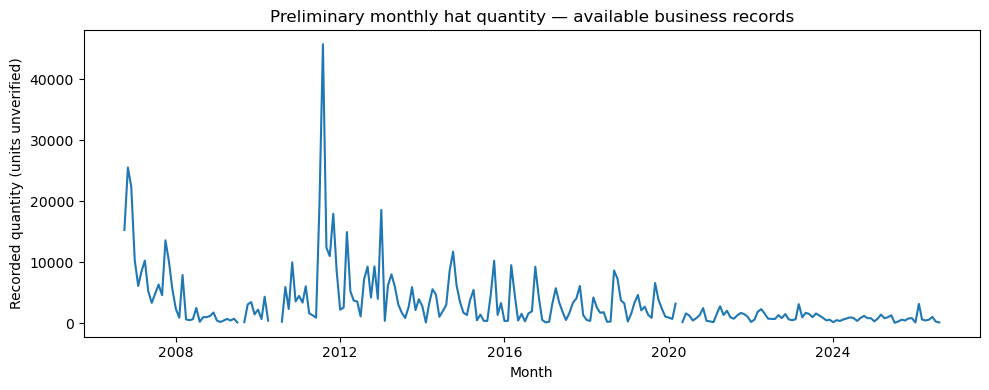

In [12]:
# Plot monthly quantities, leaving unknown months as gaps.
plt.figure(figsize=(10, 4))
plt.plot(monthly_total.index, monthly_total.values)
plt.title('Preliminary monthly hat quantity — available business records')
plt.xlabel('Month')
plt.ylabel('Recorded quantity (units unverified)')
plt.tight_layout()
plt.show()


#### Material composition and invoice quantities
Compare provisional materials and show order quantities on a log-scaled axis to display both small and large orders.


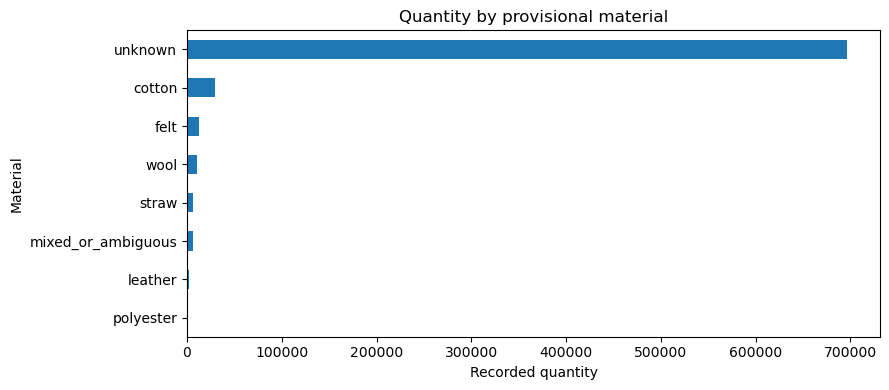

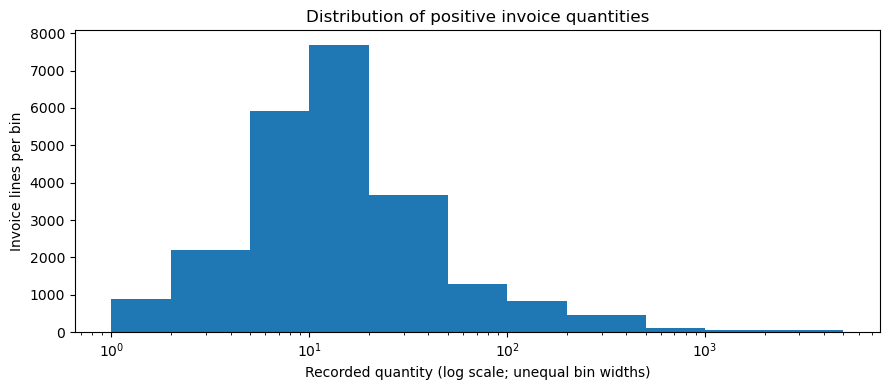

In [13]:
# Compare total recorded quantities by provisional material.
material_totals = clean_sales.groupby('material')['quantity'].sum().sort_values()
material_totals.plot(kind='barh', figsize=(9, 4))
plt.title('Quantity by provisional material')
plt.xlabel('Recorded quantity')
plt.ylabel('Material')
plt.tight_layout()
plt.show()

# Use wider bins for larger orders and label the axis in original quantities.
plt.figure(figsize=(9, 4))
plt.hist(clean_sales['quantity'], bins=[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 5000])
plt.xscale('log')
plt.title('Distribution of positive invoice quantities')
plt.xlabel('Recorded quantity (log scale; unequal bin widths)')
plt.ylabel('Invoice lines per bin')
plt.tight_layout()
plt.show()


#### Material patterns over time
Compare cotton, felt, and wool, the three largest named groups. Missing observations remain gaps.


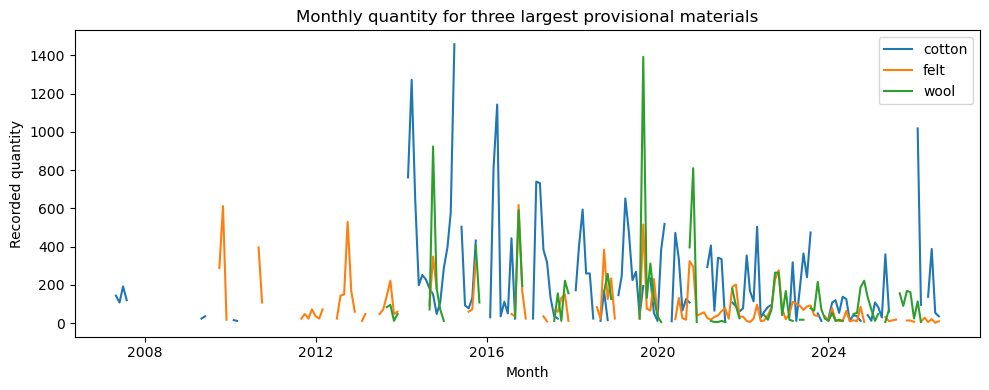

In [14]:
# Find the three largest named material groups.
known = monthly_sales[~monthly_sales['material'].isin(['unknown', 'mixed_or_ambiguous'])]
material_totals = known.groupby('material')['recorded_quantity'].sum().sort_values(ascending=False)
top_materials = material_totals.head(3).index

plt.figure(figsize=(10, 4))
for material in top_materials:
    material_data = known[known['material'] == material]
    quantities = material_data.set_index('month')['recorded_quantity'].reindex(month_range)
    plt.plot(quantities.index, quantities.values, label=material)
plt.title('Monthly quantity for three largest provisional materials')
plt.xlabel('Month')
plt.ylabel('Recorded quantity')
plt.legend()
plt.tight_layout()
plt.show()


#### National weather over the sales date range
Summarize weather once per month to avoid counting it repeatedly across materials.


,temperature_c,precipitation_mm
count,239.00,239.00
mean,12.10,65.62
std,8.42,14.80
min,-1.58,24.38
25%,4.59,56.39
50%,11.98,65.28
75%,20.31,75.06
max,24.95,113.54


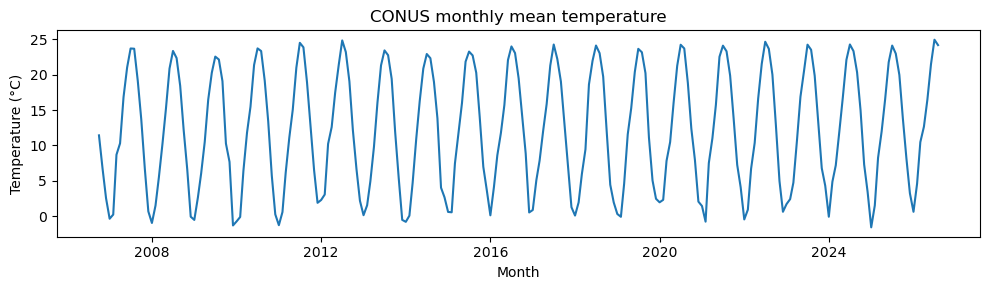

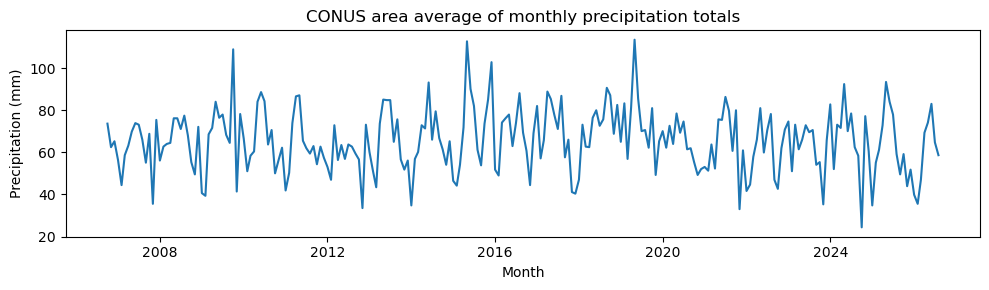

In [15]:
# Describe the national weather series within the sales date range.
display(weather_monthly[['temperature_c', 'precipitation_mm']].describe().round(2))

plt.figure(figsize=(10, 3))
plt.plot(weather_monthly['month'], weather_monthly['temperature_c'])
plt.title('CONUS monthly mean temperature')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(weather_monthly['month'], weather_monthly['precipitation_mm'])
plt.title('CONUS area average of monthly precipitation totals')
plt.xlabel('Month')
plt.ylabel('Precipitation (mm)')
plt.tight_layout()
plt.show()


#### Interpretation and research-question update
- We retain **23,072 invoice lines** across **234 months**, with five missing sales months in the calendar.
- Invoice quantity has a median of **12** and mean of **33.13**. Monthly totals have a median of **1,528.5** and mean of **3,266.54**, indicating right skew.
- **91.9%** of quantity lacks a clear material label, limiting material comparisons.
- All **813 month–material rows** match weather. Across 239 calendar months, mean temperature is **12.10 °C** and mean monthly precipitation is **65.62 mm**.

We refined the question to specify CONUS climate. Seasonal temperature patterns support including month-of-year controls. Before modeling, verify sales coverage, quantity units, and material labels; weather associations have not yet been tested.


### 6. Questions for peer reviewers and project mentor — Part 1
1. How can we verify completeness of the possibly capped sales export?
2. Is CONUS climate appropriate, or do we need customer-region data?
3. Should sales include returns and credits?
4. How should we handle trim, mixed materials, and unknown labels?
5. How can we distinguish missing months from true zero sales?

The group will discuss and finalize these questions.


## Part 2 — Preregistration of analyses

### Questions for reviewers and project mentor — Part 2
1. Do two interaction tests in one model satisfy the two-analysis requirement?
2. Is log-transformed quantity with seasonal controls appropriate?
3. What course-level method handles dependence between monthly observations?
4. Is there enough weather variation after seasonal adjustment?
5. Would wholesale ordering justify a pre-specified lagged-weather analysis?

### Submission checklist
- [x] Clean and merge sales/weather; execute cells and save outputs.
- [x] Include descriptions, limitations, EDA, and reviewer questions.
- [ ] Verify sales coverage, units, and material labels.
- [ ] Add source release/download details and approved data-access links.
- [ ] Discuss reviewer questions and finalize preregistrations before testing.
- [ ] After final edits, rerun and export one combined PDF for Gradescope.
